In [11]:
# Load the CNN baseline and the CNN+AKF tracker, and define a clip runner for each.

import csv
import math
import time
from dataclasses import dataclass
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml

ROOT = Path.cwd().resolve()
if not (ROOT / "configs" / "base_akf.yaml").is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.crop_dataloader import SRC_H, SRC_W, _crop
from models.baseline_cnn.model import BaselineCNN
from models.detection.cnn_detector.model import CNNDetector
from models.ssm.base_akf.model import SSM
from models.ssm.base_akf.track import inside

BASELINE_DIR = "models/baseline_cnn/saved_models/baseline_cnn_train1"
CNN_DIR = "models/detection/cnn_detector/saved_models/cnn_detector"

# Same detector settings as notebooks/test_base_akf_cnn.ipynb.
CONF_MIN = 0.60
PEAK_FRAC = 0.30
MIN_SIDE, SIDE_STEP, MAX_SIDE, MULTIPLE = 48, 48, 720, 4
R_MIN, R_MAX = 2.0, 40.0

VISIBILITY = {0: "not in frame", 1: "visible", 2: "hard to see", 3: "occluded"}
MOVEMENT = {0: "flying", 1: "hit", 2: "bouncing"}

with (ROOT / "configs" / "base_akf.yaml").open() as f:
    cfg = yaml.safe_load(f)
dataset = Path(cfg["paths"]["dataset"])
if not dataset.is_absolute():
    cfg["paths"]["dataset"] = str((ROOT / dataset).resolve())


def n_params(module: torch.nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())


def _load_run(folder: str) -> tuple[Path, dict, dict]:
    run_dir = Path(folder)
    if not run_dir.is_absolute():
        run_dir = ROOT / run_dir
    with (run_dir / "config.yaml").open() as f:
        run_cfg = yaml.safe_load(f)
    checkpoint = next(run_dir.glob("*.pt"))
    state = torch.load(checkpoint, map_location="cpu", weights_only=True)
    return checkpoint, run_cfg, state


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

base_ckpt, base_cfg, base_state = _load_run(BASELINE_DIR)
num_frames = int(base_cfg["model"]["num_frames"])
channels_per_frame = int(base_cfg["model"]["channels_per_frame"])
in_ch = num_frames * channels_per_frame
out_w = int(base_cfg["image"]["width"])
out_h = int(base_cfg["image"]["height"])
baseline = BaselineCNN(num_frames, channels_per_frame).to(device).eval()
baseline.load_state_dict(base_state["model"])

cnn_ckpt, cnn_cfg, cnn_state = _load_run(CNN_DIR)
num_diffs = int(cnn_cfg["model"]["num_diffs"])
cnn = CNNDetector(in_channels=num_diffs).to(device).eval()
cnn.load_state_dict(cnn_state["model"])

print(
    f"baseline  {base_ckpt.relative_to(ROOT)}  {device}  "
    f"params={n_params(baseline):,}  input={in_ch}x{out_h}x{out_w}"
)
print(
    f"cnn+akf   {cnn_ckpt.relative_to(ROOT)}  {device}  "
    f"params={n_params(cnn):,}  diffs={num_diffs}  crop={MIN_SIDE}..{MAX_SIDE}  "
    f"(AKF has no weights)"
)

# Crop side -> number of detector images run at that side. Cell 2 clears this.
forward_counts: dict[int, int] = {}
_frame_forwards: list[tuple[int, int]] = []


def _sync() -> None:
    if device.type == "cuda":
        torch.cuda.synchronize()


def load_clip(game: str, clip: str) -> list[dict]:
    clip_dir = Path(cfg["paths"]["dataset"]) / game / clip
    frames = []
    with (clip_dir / "Label.csv").open(newline="") as f:
        for row in csv.DictReader(f):
            vis = int(row["visibility"] or 0)
            xy = None
            if vis > 0:
                xy = np.array(
                    [float(row["x-coordinate"]), float(row["y-coordinate"])],
                    dtype=np.float64,
                )
            frames.append(
                {
                    "file": row["file name"],
                    "path": clip_dir / row["file name"],
                    "visibility": vis,
                    "status": int(row["status"] or 0),
                    "xy": xy,
                }
            )
    return frames


def read_gray(path: Path) -> np.ndarray:
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
        gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return gray


def read_rgb(path: Path) -> np.ndarray:
    """Model-resolution RGB, channel-first, matching BallDataset."""
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    if bgr.shape[1] != out_w or bgr.shape[0] != out_h:
        bgr = cv2.resize(bgr, (out_w, out_h), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return np.ascontiguousarray(rgb.transpose(2, 0, 1))


def frame_diffs(grays: list[np.ndarray], i: int) -> list[np.ndarray] | None:
    if i < num_diffs:
        return None
    window = grays[i - num_diffs : i + 1]
    return [
        (window[k].astype(np.float32) - window[k - 1].astype(np.float32)) / 255.0
        for k in range(1, len(window))
    ]


def _ladder() -> list[int]:
    limit = max(MIN_SIDE, min(MAX_SIDE, max(SRC_W, SRC_H)))
    side = MIN_SIDE
    sides = [side]
    step = max(SIDE_STEP, MULTIPLE)
    while side < limit:
        side = min(limit, side + step)
        if side != sides[-1]:
            sides.append(side)
    return sides


@dataclass
class Meas:
    xy: np.ndarray | None
    spread: float
    spread_x: float
    spread_y: float
    conf: float


def measurement_std(spread: float) -> float:
    if not np.isfinite(spread):
        return R_MAX
    return float(np.clip(spread, R_MIN, R_MAX))


def _miss() -> Meas:
    return Meas(None, float("nan"), float("nan"), float("nan"), float("nan"))


def decode(heat: np.ndarray) -> Meas:
    conf = float(heat.max()) if heat.size else 0.0
    if conf < CONF_MIN:
        return Meas(None, float("nan"), float("nan"), float("nan"), conf)
    ys, xs = np.nonzero(heat >= PEAK_FRAC * conf)
    weight = heat[ys, xs].astype(np.float64)
    weight /= weight.sum()
    mx = float(xs @ weight)
    my = float(ys @ weight)
    var_x = float(((xs - mx) ** 2) @ weight)
    var_y = float(((ys - my) ** 2) @ weight)
    return Meas(
        np.array([mx, my], dtype=np.float64),
        math.sqrt(max(0.0, 0.5 * (var_x + var_y))),
        math.sqrt(max(var_x, 0.0)),
        math.sqrt(max(var_y, 0.0)),
        conf,
    )


def _stack(diffs: list[np.ndarray], x0: int, y0: int, side: int) -> np.ndarray:
    return np.stack([_crop(d, x0, y0, side, side) for d in diffs], axis=0)


def _forward(crops: list[np.ndarray]) -> np.ndarray:
    side = int(crops[0].shape[-1])
    n = len(crops)
    forward_counts[side] = forward_counts.get(side, 0) + n
    _frame_forwards.append((side, n))
    batch = torch.from_numpy(np.stack(crops)).to(device)
    with torch.inference_mode():
        return cnn(batch)[:, 0].detach().cpu().numpy()


def _axis_origins(lo: float, hi: float, side: int, frame: int) -> list[int]:
    lo_i = max(0, int(math.floor(lo)))
    hi_i = min(frame, int(math.ceil(hi)))
    last = max(0, frame - side)
    if hi_i <= lo_i:
        return [0]
    if hi_i - lo_i <= side:
        origin = lo_i + (hi_i - lo_i - side) // 2
        return [min(max(0, origin), last)]
    stride = max(MULTIPLE, side // 2)
    first = min(max(0, lo_i), last)
    end = min(max(0, hi_i - side), last)
    if end < first:
        first, end = end, first
    origins = list(range(first, end + 1, stride))
    if origins[-1] != end:
        origins.append(end)
    return origins


def _search_origins(side: int, box=None) -> list[tuple[int, int]]:
    if box is None:
        box = (0.0, 0.0, float(SRC_W), float(SRC_H))
    xs = _axis_origins(box[0], box[2], side, SRC_W)
    ys = _axis_origins(box[1], box[3], side, SRC_H)
    return [(x, y) for y in ys for x in xs]


def _search(diffs: list[np.ndarray], box=None) -> Meas:
    """Best peak on MAX_SIDE tiles. box limits the tiles and the peak."""
    origins = _search_origins(MAX_SIDE, box)
    best: Meas | None = None
    best_conf = -1.0
    low_conf = float("nan")
    for start in range(0, len(origins), 16):
        chunk = origins[start : start + 16]
        heats = _forward([_stack(diffs, x0, y0, MAX_SIDE) for x0, y0 in chunk])
        for (x0, y0), heat in zip(chunk, heats):
            meas = decode(heat)
            if meas.xy is None:
                if not np.isfinite(low_conf) or meas.conf > low_conf:
                    low_conf = float(meas.conf)
                continue
            meas.xy = meas.xy + np.array([x0, y0], dtype=np.float64)
            if box is not None and not inside(meas.xy, box):
                continue
            if meas.conf <= best_conf:
                continue
            best = meas
            best_conf = meas.conf
    if best is not None:
        return best
    missed = _miss()
    missed.conf = low_conf
    return missed


def measure(diffs: list[np.ndarray], pred) -> Meas:
    """Grow one crop around the prediction until the ball appears or the crop is maxed.

    A smaller crop with no peak is not a miss. The frame fails only after MAX_SIDE.
    With no prediction yet, tile the whole image once to get the first lock.
    """
    if pred is None:
        return _search(diffs)
    missed = _miss()
    for side in _ladder():
        x0 = int(round(float(pred[0]) - side / 2))
        y0 = int(round(float(pred[1]) - side / 2))
        heat = _forward([_stack(diffs, x0, y0, side)])[0]
        meas = decode(heat)
        if meas.xy is None:
            if not np.isfinite(missed.conf) or meas.conf >= missed.conf:
                missed = meas
            continue
        meas.xy = meas.xy + np.array([x0, y0], dtype=np.float64)
        return meas
    return missed


def _apply(ssm: SSM, meas: Meas) -> bool:
    r_std = measurement_std(meas.spread) if meas.xy is not None else None
    ssm.update(meas.xy, r_std)
    return meas.xy is not None


def _akf_step(ssm: SSM, meas: Meas, used: bool, ms: float) -> dict:
    return {
        "xy": ssm.mean[:2].copy(),
        "conf": float(meas.conf),
        "used": used,
        "ms": ms,
        "forwards": list(_frame_forwards),
    }


def run_baseline(frames: list[dict]) -> list[dict | None]:
    """Heatmap argmax in source pixels. None until the N-frame window is full.

    Frames are read before the timer. ms covers the stack, the forward, and the argmax.
    """
    rgbs = [read_rgb(frame["path"]) for frame in frames]
    steps: list[dict | None] = []
    for i in range(len(frames)):
        if i < num_frames - 1:
            steps.append(None)
            continue
        _sync()
        t0 = time.perf_counter()
        window = rgbs[i - num_frames + 1 : i + 1]
        x = torch.from_numpy(np.concatenate(window, axis=0)).unsqueeze(0).to(device)
        with torch.inference_mode():
            heat = baseline(x)[0, 0]
        conf = float(heat.amax().item())
        flat = int(heat.argmax().item())
        height, width = heat.shape
        xy = np.array(
            [(flat % width) * (SRC_W / width), (flat // width) * (SRC_H / height)],
            dtype=np.float64,
        )
        _sync()
        steps.append({"xy": xy, "conf": conf, "ms": (time.perf_counter() - t0) * 1000.0})
    return steps


def run_akf(frames: list[dict]) -> list[dict | None]:
    """CNN crop ladder plus AKF posterior. None until the first accepted peak.

    Frames are read before the timer. ms covers the difference, the crops, and the update.
    Each step records detector forwards as (crop side, count) for the FLOP total.
    """
    grays = [read_gray(frame["path"]) for frame in frames]
    ssm = SSM(cfg["tracker"])
    steps: list[dict | None] = []
    for i in range(len(frames)):
        if i < num_diffs:
            steps.append(None)
            continue
        _frame_forwards.clear()
        _sync()
        t0 = time.perf_counter()
        diffs = frame_diffs(grays, i)
        if ssm.mean is None:
            meas = measure(diffs, None)
            if meas.xy is None:
                _sync()
                steps.append(None)
                continue
            ssm.initiate(meas.xy)
            _sync()
            steps.append(_akf_step(ssm, meas, True, (time.perf_counter() - t0) * 1000.0))
            continue
        ssm.predict()
        pred = ssm.mean[:2].copy()
        meas = measure(diffs, pred)
        used = _apply(ssm, meas)
        _sync()
        steps.append(_akf_step(ssm, meas, used, (time.perf_counter() - t0) * 1000.0))
    return steps


baseline  models/baseline_cnn/saved_models/baseline_cnn_train1/baseline_cnn_train1.pt  cuda  params=11,334,017  input=9x360x640
cnn+akf   models/detection/cnn_detector/saved_models/cnn_detector/cnn_detector.pt  cuda  params=118,769  diffs=2  crop=48..720  (AKF has no weights)


game10/Clip1
game10/Clip10
game10/Clip11
game10/Clip12
game10/Clip2
game10/Clip3
game10/Clip4
game10/Clip5
game10/Clip6
game10/Clip7
game10/Clip8
game10/Clip9
test  both models have a position and the frame has a label  dist in source px  big miss > 50px
baseline = heatmap argmax    cnn+akf = filter posterior
scored=2045  skipped=37 labeled frames before both were ready
baseline          n= 2045  mean=  14.3  std=  65.6  median=   2.2  p95=  37.6  >50px=  4.5%
cnn+akf           n= 2045  mean=   6.9  std=  27.6  median=   1.5  p95=  24.8  >50px=  3.5%
movement  (mean dist)
  flying          n= 1942  base=  13.2  akf=   6.7
  hit             n=   47  base=  71.8  akf=  17.6
  bouncing        n=   56  base=   5.6  akf=   7.0
obscurity  (mean dist)
  visible         n= 1866  base=   8.7  akf=   6.8
  hard to see     n=  178  base=  71.2  akf=   8.6
  occluded        n=    1  base= 424.4  akf=   1.3


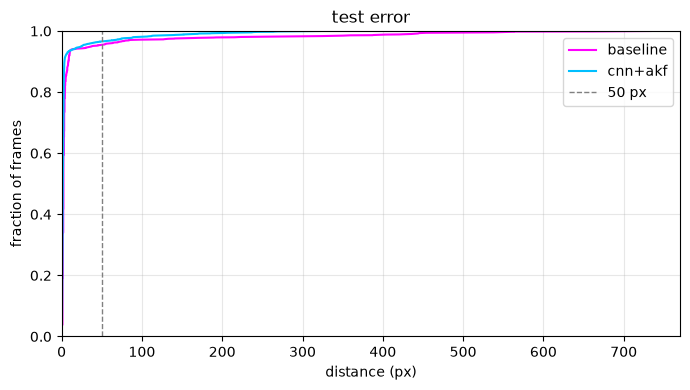

pipeline ms is after the frames are in memory (stack or crop, forward, decode, AKF update)
baseline          params=11,334,017  flops mean=350.65 G  p95=350.65 G  ms mean= 17.45  std=  0.17  p95= 17.79   15.9 ms under 33.3
cnn+akf           params=   118,769  flops mean= 17.68 G  p95=159.72 G  ms mean=  5.12  std= 10.78  p95= 36.16   28.2 ms under 33.3
one forward  baseline 350.65 G  cnn@48 128.80 M
forward only  warmup=10  repeats=50  baseline  16.63 ms  cnn 48px   0.40 ms


In [12]:
# Score both models on the same labeled frames. Distance is source pixels.

from torch.utils.flop_counter import FlopCounterMode

SPLIT = "test"
BIG_MISS_PX = 50.0
FRAME_MS = 1000.0 / 30.0
WARMUP, REPEATS = 10, 50


def count_flops(module: torch.nn.Module, example: torch.Tensor) -> int:
    with torch.inference_mode():
        with FlopCounterMode(display=False) as counter:
            module(example)
    return int(counter.get_total_flops())


def fmt_flops(n: float) -> str:
    if n >= 1e9:
        return f"{n / 1e9:.2f} G"
    if n >= 1e6:
        return f"{n / 1e6:.2f} M"
    return f"{n / 1e3:.1f} K"


flop_cnn = {
    side: count_flops(cnn, torch.zeros(1, num_diffs, side, side, device=device))
    for side in _ladder()
}
base_flops_one = count_flops(
    baseline, torch.zeros(1, in_ch, out_h, out_w, device=device)
)

# The timed pass should not include the first CUDA launch.
with torch.inference_mode():
    baseline(torch.zeros(1, in_ch, out_h, out_w, device=device))
    cnn(torch.zeros(1, num_diffs, MIN_SIDE, MIN_SIDE, device=device))
_sync()

forward_counts.clear()
base_err, akf_err = [], []
base_ms, akf_ms = [], []
base_flops, akf_flops = [], []
visibility, movement = [], []
skipped = 0

root = Path(cfg["paths"]["dataset"])
for game in cfg["splits"][SPLIT]:
    game_dir = root / game
    if not game_dir.is_dir():
        raise FileNotFoundError(game_dir)
    for clip_dir in sorted(p for p in game_dir.iterdir() if p.is_dir()):
        print(f"{game}/{clip_dir.name}", flush=True)
        frames = load_clip(game, clip_dir.name)
        base_steps = run_baseline(frames)
        akf_steps = run_akf(frames)
        for frame, b, a in zip(frames, base_steps, akf_steps):
            if frame["xy"] is None:
                continue
            if b is None or a is None:
                skipped += 1
                continue
            base_err.append(float(np.hypot(*(b["xy"] - frame["xy"]))))
            akf_err.append(float(np.hypot(*(a["xy"] - frame["xy"]))))
            base_ms.append(b["ms"])
            akf_ms.append(a["ms"])
            base_flops.append(base_flops_one)
            akf_flops.append(sum(n * flop_cnn[side] for side, n in a["forwards"]))
            visibility.append(frame["visibility"])
            movement.append(frame["status"])

base_err = np.asarray(base_err, dtype=np.float64)
akf_err = np.asarray(akf_err, dtype=np.float64)
base_ms = np.asarray(base_ms, dtype=np.float64)
akf_ms = np.asarray(akf_ms, dtype=np.float64)
base_flops = np.asarray(base_flops, dtype=np.float64)
akf_flops = np.asarray(akf_flops, dtype=np.float64)
visibility = np.asarray(visibility)
movement = np.asarray(movement)

print(
    f"{SPLIT}  both models have a position and the frame has a label  "
    f"dist in source px  big miss > {BIG_MISS_PX:.0f}px"
)
print("baseline = heatmap argmax    cnn+akf = filter posterior")
print(f"scored={len(base_err)}  skipped={skipped} labeled frames before both were ready")


def show_accuracy(name: str, errs: np.ndarray) -> None:
    if len(errs) == 0:
        print(f"{name:16}  n=    0")
        return
    big = 100.0 * np.mean(errs > BIG_MISS_PX)
    print(
        f"{name:16}  n={len(errs):5d}  "
        f"mean={errs.mean():6.1f}  std={errs.std():6.1f}  "
        f"median={np.median(errs):6.1f}  p95={np.percentile(errs, 95):6.1f}  "
        f">{BIG_MISS_PX:.0f}px={big:5.1f}%"
    )


def show_group(name: str, mask: np.ndarray) -> None:
    count = int(mask.sum())
    if count == 0:
        return
    print(
        f"{name:16}  n={count:5d}  "
        f"base={base_err[mask].mean():6.1f}  "
        f"akf={akf_err[mask].mean():6.1f}"
    )


if len(base_err) == 0:
    print("no scored frames")
else:
    show_accuracy("baseline", base_err)
    show_accuracy("cnn+akf", akf_err)
    print("movement  (mean dist)")
    for code, name in MOVEMENT.items():
        show_group(f"  {name}", movement == code)
    print("obscurity  (mean dist)")
    for code, name in VISIBILITY.items():
        if code == 0:
            continue
        show_group(f"  {name}", visibility == code)

    fig, ax = plt.subplots(figsize=(7.0, 4.0))
    for errs, label, color in (
        (base_err, "baseline", "magenta"),
        (akf_err, "cnn+akf", "deepskyblue"),
    ):
        ordered = np.sort(errs)
        ax.plot(
            ordered,
            np.arange(1, len(ordered) + 1) / len(ordered),
            color=color,
            label=label,
        )
    ax.axvline(BIG_MISS_PX, color="0.5", ls="--", lw=1, label=f"{BIG_MISS_PX:.0f} px")
    ax.set_xlim(left=0)
    ax.set_ylim(0, 1)
    ax.set_xlabel("distance (px)")
    ax.set_ylabel("fraction of frames")
    ax.set_title(f"{SPLIT} error")
    ax.legend()
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()

    def show_cost(name: str, params: int, flops: np.ndarray, ms: np.ndarray) -> None:
        gap = FRAME_MS - float(ms.mean())
        side = "under" if gap >= 0 else "over"
        print(
            f"{name:16}  params={params:10,}  "
            f"flops mean={fmt_flops(flops.mean()):>8}  p95={fmt_flops(np.percentile(flops, 95)):>8}  "
            f"ms mean={ms.mean():6.2f}  std={ms.std():6.2f}  p95={np.percentile(ms, 95):6.2f}  "
            f"{abs(gap):5.1f} ms {side} {FRAME_MS:.1f}"
        )

    print(
        "pipeline ms is after the frames are in memory "
        "(stack or crop, forward, decode, AKF update)"
    )
    show_cost("baseline", n_params(baseline), base_flops, base_ms)
    show_cost("cnn+akf", n_params(cnn), akf_flops, akf_ms)

    common_side = max(forward_counts, key=forward_counts.get) if forward_counts else MIN_SIDE
    base_x = torch.zeros(1, in_ch, out_h, out_w, device=device)
    cnn_x = torch.zeros(1, num_diffs, common_side, common_side, device=device)

    def forward_ms(fn) -> float:
        for _ in range(WARMUP):
            fn()
        _sync()
        t0 = time.perf_counter()
        for _ in range(REPEATS):
            fn()
        _sync()
        return (time.perf_counter() - t0) / REPEATS * 1000.0

    def run_base():
        with torch.inference_mode():
            baseline(base_x)

    def run_cnn():
        with torch.inference_mode():
            cnn(cnn_x)

    print(f"one forward  baseline {fmt_flops(base_flops_one)}  cnn@{common_side} {fmt_flops(flop_cnn[common_side])}")
    print(
        f"forward only  warmup={WARMUP}  repeats={REPEATS}  "
        f"baseline {forward_ms(run_base):6.2f} ms  "
        f"cnn {common_side}px {forward_ms(run_cnn):6.2f} ms"
    )


game10/Clip4  0001.jpg → 0046.jpg
file        move      vis              base      akf  closer
0001.jpg    flying    hard to see         —        —  —
0002.jpg    flying    visible           1.4      1.5  tie
0003.jpg    flying    visible           2.2      1.0  akf
0004.jpg    flying    visible           2.0      0.9  akf
0005.jpg    flying    visible           1.0      0.9  akf
0006.jpg    flying    visible           2.0      1.9  akf
0007.jpg    flying    visible           1.0      0.4  akf
0008.jpg    flying    visible           1.0      1.2  base
0009.jpg    flying    visible           2.0      1.6  akf
0010.jpg    hit       visible         445.3     27.3  akf
0011.jpg    flying    visible           2.2      2.0  akf
0012.jpg    flying    visible           1.0      0.9  akf
0013.jpg    flying    visible           2.8      2.3  akf
0014.jpg    flying    visible           0.0      0.8  base
0015.jpg    flying    visible           1.0      0.6  akf
0016.jpg    flying    visible      

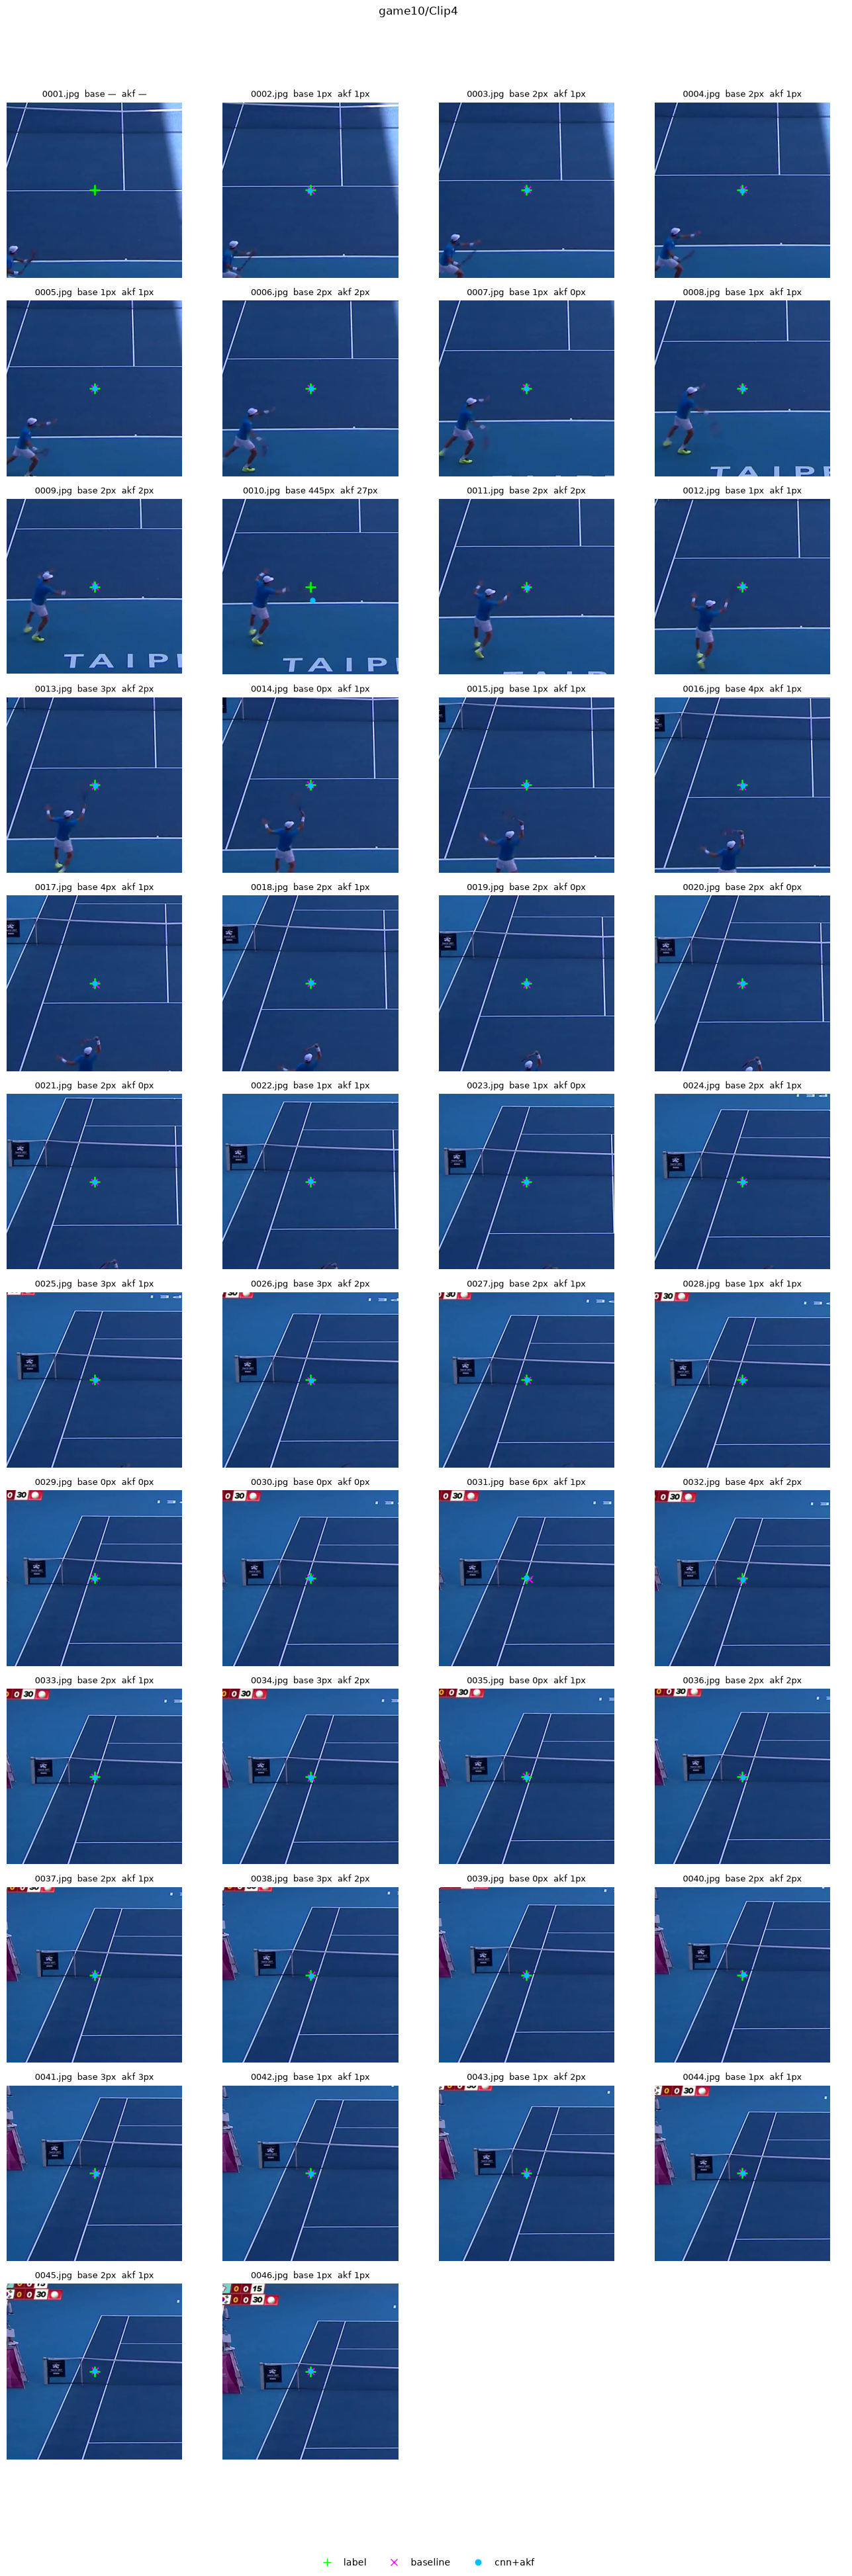

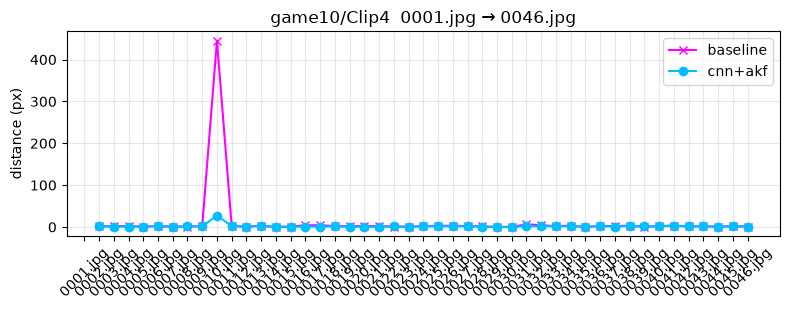

In [15]:
# Both models on one clip. Change the clip here.

from matplotlib.lines import Line2D

GAME, CLIP = "game10", "Clip4"
START, COUNT = "0001.jpg", 50

clip = load_clip(GAME, CLIP)
start = next(i for i, frame in enumerate(clip) if frame["file"] == START)
end = min(start + COUNT, len(clip))
window = range(start, end)
base_steps = run_baseline(clip)
akf_steps = run_akf(clip)

print(f"{GAME}/{CLIP}  {clip[start]['file']} → {clip[end - 1]['file']}")
print(f"{'file':10}  {'move':8}  {'vis':12}  {'base':>7}  {'akf':>7}  closer")

base_window, akf_window = [], []
for i in window:
    frame, b, a = clip[i], base_steps[i], akf_steps[i]
    xy = frame["xy"]
    be = float(np.hypot(*(b["xy"] - xy))) if b is not None and xy is not None else float("nan")
    ae = float(np.hypot(*(a["xy"] - xy))) if a is not None and xy is not None else float("nan")
    base_window.append(be)
    akf_window.append(ae)
    if np.isfinite(be) and np.isfinite(ae):
        if abs(be - ae) < 0.05:
            closer = "tie"
        elif be < ae:
            closer = "base"
        else:
            closer = "akf"
    else:
        closer = "—"
    be_txt = f"{be:7.1f}" if np.isfinite(be) else "      —"
    ae_txt = f"{ae:7.1f}" if np.isfinite(ae) else "      —"
    print(
        f"{frame['file']:10}  {MOVEMENT[frame['status']]:8}  "
        f"{VISIBILITY[frame['visibility']]:12}  {be_txt}  {ae_txt}  {closer}"
    )

base_window = np.asarray(base_window, dtype=np.float64)
akf_window = np.asarray(akf_window, dtype=np.float64)
both = np.isfinite(base_window) & np.isfinite(akf_window)
n_both = int(both.sum())
if n_both == 0:
    print("no labeled frame in this window with both positions")
else:
    print(
        f"window  n={n_both}  "
        f"base mean={base_window[both].mean():.1f}  "
        f"median={np.median(base_window[both]):.1f}  "
        f"std={base_window[both].std():.1f}  "
        f"akf mean={akf_window[both].mean():.1f}  "
        f"median={np.median(akf_window[both]):.1f}  "
        f"std={akf_window[both].std():.1f}"
    )

half = 180
ncols = 4
nrows = int(np.ceil(len(window) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.3 * ncols, 3.3 * nrows))
for ax, i in zip(np.atleast_1d(axes).ravel(), window):
    frame, b, a = clip[i], base_steps[i], akf_steps[i]
    bgr = cv2.imread(str(frame["path"]), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(frame["path"])
    if bgr.shape[1] != SRC_W or bgr.shape[0] != SRC_H:
        bgr = cv2.resize(bgr, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    xy = frame["xy"]
    if xy is not None:
        center = xy
    elif a is not None:
        center = a["xy"]
    elif b is not None:
        center = b["xy"]
    else:
        center = np.array([SRC_W / 2, SRC_H / 2])
    if xy is not None:
        ax.plot(*xy, "+", color="lime", ms=11, mew=1.8)
    if b is not None:
        ax.plot(*b["xy"], "x", color="magenta", ms=7, mew=1.4)
    if a is not None:
        ax.plot(*a["xy"], "o", color="deepskyblue", ms=5)
    ax.set_xlim(center[0] - half, center[0] + half)
    ax.set_ylim(center[1] + half, center[1] - half)
    be = f"{base_window[i - start]:.0f}px" if np.isfinite(base_window[i - start]) else "—"
    ae = f"{akf_window[i - start]:.0f}px" if np.isfinite(akf_window[i - start]) else "—"
    ax.set_title(f"{frame['file']}  base {be}  akf {ae}", fontsize=9)
    ax.axis("off")

for ax in np.atleast_1d(axes).ravel()[len(window) :]:
    ax.axis("off")

fig.legend(
    handles=[
        Line2D([0], [0], marker="+", color="lime", lw=0, ms=8, label="label"),
        Line2D([0], [0], marker="x", color="magenta", lw=0, ms=7, label="baseline"),
        Line2D([0], [0], marker="o", color="deepskyblue", lw=0, ms=6, label="cnn+akf"),
    ],
    loc="lower center",
    ncol=3,
    frameon=False,
)
fig.suptitle(f"{GAME}/{CLIP}", fontsize=12)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
plt.show()

fig, ax = plt.subplots(figsize=(8.0, 3.2))
names = [clip[i]["file"] for i in window]
ax.plot(names, base_window, color="magenta", marker="x", label="baseline")
ax.plot(names, akf_window, color="deepskyblue", marker="o", label="cnn+akf")
ax.set_ylabel("distance (px)")
ax.set_title(f"{GAME}/{CLIP}  {clip[start]['file']} → {clip[end - 1]['file']}")
ax.tick_params(axis="x", labelrotation=45)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
